# 01 — Exploration des données (EDA) — Perturb-seq Cross-Line

1. **Intégrité & schéma de validation** : vérifier les `NaN`, la construction de `fold == "val"` vs `test.csv`, et concevoir notre validation croisée (`GroupKFold` sur `target_gene`).
2. **Couverture des lignées sources** : de combien de lignées (et lesquelles) dispose-t-on pour prédire chaque entrée de `val` et `test` ?
3. **Matrice de similarité inter-lignées ($6 \times 6$)** : quelles paires de lignées corrèlent le mieux, et quelles différences d'amplitude (variance) existent entre laboratoires ?
4. **Effet de `n_cells`** : les profils avec peu de cellules sont-ils plus bruités (pondération par $n_{\text{cells}}$) ?
5. **Rôle de `baseline_expression.csv`** : l'expression basale du gène knock-downé prédit-elle la force de sa réponse ?
6. **Structure des 6 546 gènes vs 500 gènes scorés** : spectre SVD/PCA (dimension intrinsèque) et rôle de `line_mean_response.csv`.
7. **Diagnostic  des erreurs de la baseline `00_baseline`** : pourquoi Jurkat score plus bas (`0.379`) et où sont les plus gros gains faciles ?

In [11]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import (
    load_baseline_expression,
    load_genes,
    load_line_mean_response,
    load_test,
    load_train,
)

plt.rcParams.update({
    "figure.dpi": 115,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

print(f"Racine projet : {ROOT}")

Racine projet : /Users/victor/Documents/crispri-response-prediction


---
## 1. Chargement, dimensions, mémoire et valeurs manquantes.

In [12]:
train_df = load_train()
test_df = load_test()
genes_raw = load_genes()
baseline_raw = load_baseline_expression()
line_mean_raw = load_line_mean_response()

print("Retour de load_genes() :", [type(x).__name__ for x in genes_raw] if isinstance(genes_raw, tuple) else type(genes_raw).__name__)

if isinstance(genes_raw, tuple):
    dfs = [x for x in genes_raw if isinstance(x, pd.DataFrame)]
    genes_df = dfs[0] if dfs else pd.read_csv(ROOT / "data" / "genes.csv")
else:
    genes_df = genes_raw

if "gene_id" not in genes_df.columns and genes_df.index.name == "gene_id":
    genes_df = genes_df.reset_index()

all_genes = genes_df["gene_id"].tolist()
scored_genes = genes_df.loc[genes_df["scored"], "gene_id"].tolist()
unscored_genes = genes_df.loc[~genes_df["scored"], "gene_id"].tolist()
meta_cols = [c for c in train_df.columns if c not in set(all_genes)]

print(f"train.parquet       : {train_df.shape} | RAM: {train_df.memory_usage(deep=True).sum() / 1e6:.1f} Mo")
print(f"test.csv            : {test_df.shape}")
print(f"genes.csv           : {genes_df.shape} (scored={len(scored_genes)}, unscored={len(unscored_genes)})")
print(f"baseline_expression : {baseline_raw.shape}")
print(f"line_mean_response  : {line_mean_raw.shape}")
print(f"Colonnes méta train : {meta_cols}")
print(f"Colonnes test       : {list(test_df.columns)}")

Retour de load_genes() : ['DataFrame', 'list', 'list']
train.parquet       : (8497, 6553) | RAM: 225.1 Mo
test.csv            : (3278, 4)
genes.csv           : (6546, 3) (scored=500, unscored=6046)
baseline_expression : (6, 6549)
line_mean_response  : (6, 6547)
Colonnes méta train : ['id', 'line', 'target_gene', 'target_symbol', 'n_cells', 'fold', 'extra_line']
Colonnes test       : ['id', 'line', 'target_gene', 'target_symbol']


In [13]:
# Vérification des NaN dans la matrice d'expression de train.parquet
Y_all = train_df[all_genes].to_numpy(dtype=np.float32)
nan_mask = np.isnan(Y_all)
total_nans = int(nan_mask.sum())

gene_to_idx = {g: i for i, g in enumerate(all_genes)}
expected_nan = np.zeros_like(nan_mask, dtype=bool)
n_targets_in_measured = 0
for row_i, tg in enumerate(train_df["target_gene"]):
    if tg in gene_to_idx:
        expected_nan[row_i, gene_to_idx[tg]] = True
        n_targets_in_measured += 1

unexpected_nans = int((nan_mask & ~expected_nan).sum())
missing_expected_nans = int((~nan_mask & expected_nan).sum())

print(f"Total NaN dans train (6 546 gènes)   : {total_nans:,}")
print(f"target_gene présents dans les 6 546  : {n_targets_in_measured:,} / {len(train_df):,}")
print(f"NaN hors target_gene   : {unexpected_nans:,}")
print(f"target_gene non-NaN : {missing_expected_nans:,}")

n_targets_in_scored = train_df["target_gene"].isin(set(scored_genes)).sum()
n_test_targets_in_scored = test_df["target_gene"].isin(set(scored_genes)).sum()
print(f"Entrées dont target_gene est parmi les 500 scorés -> train: {n_targets_in_scored:,}, test: {n_test_targets_in_scored:,}")

Total NaN dans train (6 546 gènes)   : 21,595
target_gene présents dans les 6 546  : 7,295 / 8,497
NaN hors target_gene   : 14,300
target_gene non-NaN : 0
Entrées dont target_gene est parmi les 500 scorés -> train: 1,049, test: 427


In [14]:
# Analyse du split : train vs val vs test (chevauchement des target_gene et des paires)
tr_sub = train_df.loc[train_df["fold"].eq("train")]
va_sub = train_df.loc[train_df["fold"].eq("val")]

tr_genes = set(tr_sub["target_gene"])
va_genes = set(va_sub["target_gene"])
te_genes = set(test_df["target_gene"])
all_tr_genes = set(train_df["target_gene"])

print(f"Target genes uniques — fold=='train' : {len(tr_genes):,}")
print(f"Target genes uniques — fold=='val'   : {len(va_genes):,}")
print(f"Target genes uniques — test.csv      : {len(te_genes):,}")
print(f"Val dans fold=='train'               : {len(va_genes & tr_genes):,} / {len(va_genes):,}")
print(f"Test dans train complet              : {len(te_genes & all_tr_genes):,} / {len(te_genes):,}")
print(f"Chevauchement val ∩ test (target_gene): {len(va_genes & te_genes):,}")

# Vérifie si un même target_gene apparaît plusieurs fois dans val ou test (plusieurs lignées masquées)
print("\nNombre de lignées à prédire par target_gene :")
val_per_gene = va_sub.groupby("target_gene")["line"].nunique().value_counts().sort_index()
test_per_gene = test_df.groupby("target_gene")["line"].nunique().value_counts().sort_index()
comp_masked = pd.DataFrame({"val_target_genes": val_per_gene, "test_target_genes": test_per_gene}).fillna(0).astype(int)
display(comp_masked)

Target genes uniques — fold=='train' : 2,050
Target genes uniques — fold=='val'   : 1,002
Target genes uniques — test.csv      : 1,807
Val dans fold=='train'               : 1,002 / 1,002
Test dans train complet              : 1,807 / 1,807
Chevauchement val ∩ test (target_gene): 853

Nombre de lignées à prédire par target_gene :


,val_target_genes,test_target_genes
line,,
1,837,696
2,159,751
3,6,360


---
## 2. Couverture par lignée et nombre de lignées sources disponibles

Question cruciale pour la validation croisée et le transfert : **est-ce que `fold == "val"` ressemble bien à `test.csv` en termes de lignées sources disponibles ?**
On vérifie notamment combien d'entrées dépendent uniquement des `extra_line` (HCT116 / HEK293T).

,fold_train,fold_val,test,extra_line
line,,,,
K562,957,279,814,False
Jurkat,941,287,822,False
RPE1,926,297,827,False
HepG2,925,310,815,False
HEK293T,1804,0,0,True
HCT116,1771,0,0,True



=== Sources disponibles pour fold == 'val' (N=1,173) ===
Distribution du nombre total de lignées sources :
n_src_total
1     74
2     73
3    620
4    318
5     88
Entrées avec UNIQUEMENT des extra_line (0 lignée core source) : 0 (0.0%)

=== Sources disponibles pour test.csv (N=3,278) ===
Distribution du nombre total de lignées sources :
n_src_total
1      90
2     220
3    1090
4    1298
5     580
Entrées avec UNIQUEMENT des extra_line (0 lignée core source) : 0 (0.0%)


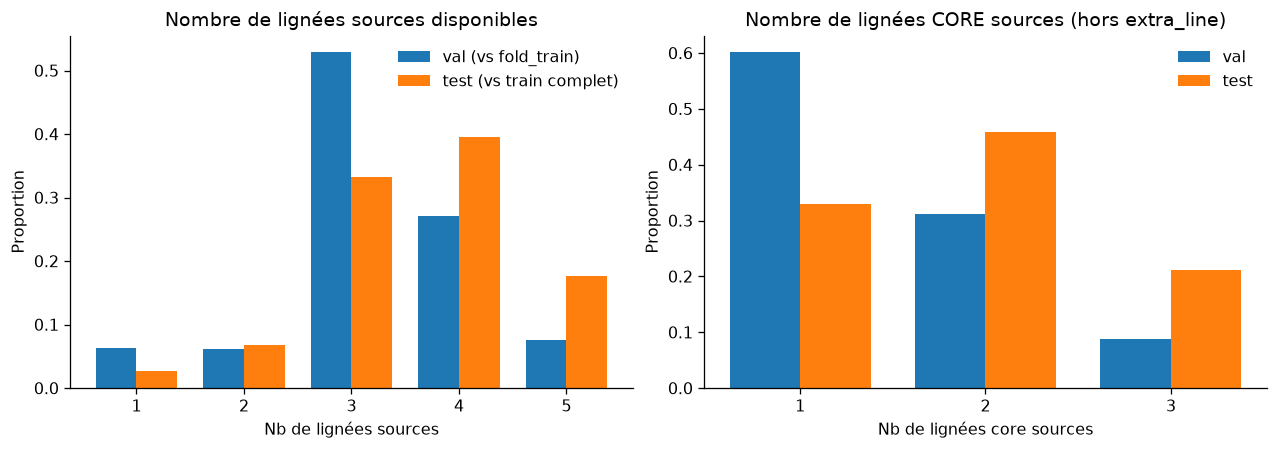

In [15]:
# Répartition des lignes par cell line
line_counts = pd.DataFrame({
    "fold_train": tr_sub["line"].value_counts(),
    "fold_val": va_sub["line"].value_counts(),
    "test": test_df["line"].value_counts(),
}).fillna(0).astype(int)
line_counts["extra_line"] = line_counts.index.isin(train_df.loc[train_df["extra_line"], "line"].unique())
display(line_counts.sort_values(["extra_line", "fold_train"], ascending=[True, False]))

# Pour chaque entrée de val (resp. test), quelles lignées sources sont disponibles ?
tr_gene_to_lines = tr_sub.groupby("target_gene")["line"].apply(set).to_dict()
full_gene_to_lines = train_df.groupby("target_gene")["line"].apply(set).to_dict()
extra_set = set(train_df.loc[train_df["extra_line"], "line"].unique())
core_set = set(train_df.loc[~train_df["extra_line"], "line"].unique())


def summarize_sources(df_eval: pd.DataFrame, source_map: dict, label: str) -> pd.DataFrame:
    rows = []
    for _, r in df_eval[["line", "target_gene"]].iterrows():
        avail = source_map.get(r["target_gene"], set()) - {r["line"]}
        n_total = len(avail)
        n_core = len(avail & core_set)
        n_extra = len(avail & extra_set)
        rows.append((r["line"], n_total, n_core, n_extra, n_core == 0))
    res = pd.DataFrame(rows, columns=["line", "n_src_total", "n_src_core", "n_src_extra", "only_extra"])
    print(f"\n=== Sources disponibles pour {label} (N={len(res):,}) ===")
    print("Distribution du nombre total de lignées sources :")
    print(res["n_src_total"].value_counts().sort_index().to_string())
    print(f"Entrées avec UNIQUEMENT des extra_line (0 lignée core source) : {res['only_extra'].sum():,} ({res['only_extra'].mean():.1%})")
    return res


val_src = summarize_sources(va_sub, tr_gene_to_lines, "fold == 'val'")
test_src = summarize_sources(test_df, full_gene_to_lines, "test.csv")

# Visualisation comparative val vs test
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")

val_dist = val_src["n_src_total"].value_counts(normalize=True).sort_index()
test_dist = test_src["n_src_total"].value_counts(normalize=True).sort_index()
all_k = sorted(set(val_dist.index) | set(test_dist.index))
x = np.arange(len(all_k))
w = 0.38
axes[0].bar(x - w / 2, [val_dist.get(k, 0) for k in all_k], width=w, label="val (vs fold_train)")
axes[0].bar(x + w / 2, [test_dist.get(k, 0) for k in all_k], width=w, label="test (vs train complet)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(all_k)
axes[0].set(title="Nombre de lignées sources disponibles", xlabel="Nb de lignées sources", ylabel="Proportion")
axes[0].legend(frameon=False)

val_core_dist = val_src["n_src_core"].value_counts(normalize=True).sort_index()
test_core_dist = test_src["n_src_core"].value_counts(normalize=True).sort_index()
all_kc = sorted(set(val_core_dist.index) | set(test_core_dist.index))
xc = np.arange(len(all_kc))
axes[1].bar(xc - w / 2, [val_core_dist.get(k, 0) for k in all_kc], width=w, label="val")
axes[1].bar(xc + w / 2, [test_core_dist.get(k, 0) for k in all_kc], width=w, label="test")
axes[1].set_xticks(xc)
axes[1].set_xticklabels(all_kc)
axes[1].set(title="Nombre de lignées CORE sources (hors extra_line)", xlabel="Nb de lignées core sources", ylabel="Proportion")
axes[1].legend(frameon=False)

plt.show()

---
## 3. Matrice de similarité inter-lignées ($6 \times 6$) & échelles des réponses


* Pour chaque paire de lignées $(A, B)$, quelle est la corrélation de Pearson moyenne sur les 500 gènes scorés pour les mêmes `target_gene` mesurés dans $A$ et $B$ ?
* Quelle est l'amplitude moyenne (norme L2 / écart-type) de chaque lignée ? Si deux lignées ont des amplitudes différentes (ex. labos différents : Replogle vs Nadig vs Xaira), une simple moyenne non normalisée est dominée par la lignée à plus forte variance !

,n_entries_train,median_n_cells,mean_row_std,median_row_std,mean_row_L2,global_std
line,,,,,,
K562,957,338.0,0.0774,0.0624,1.7567,0.0907
RPE1,926,77.5,0.1576,0.1425,3.6128,0.1735
Jurkat,941,79.0,0.1085,0.0950,2.4711,0.1217
HepG2,925,45.0,0.1236,0.1017,2.8487,0.1407
HCT116,1771,125.0,0.0657,0.0537,1.5064,0.0767
HEK293T,1804,158.0,0.0559,0.0481,1.3592,0.0690


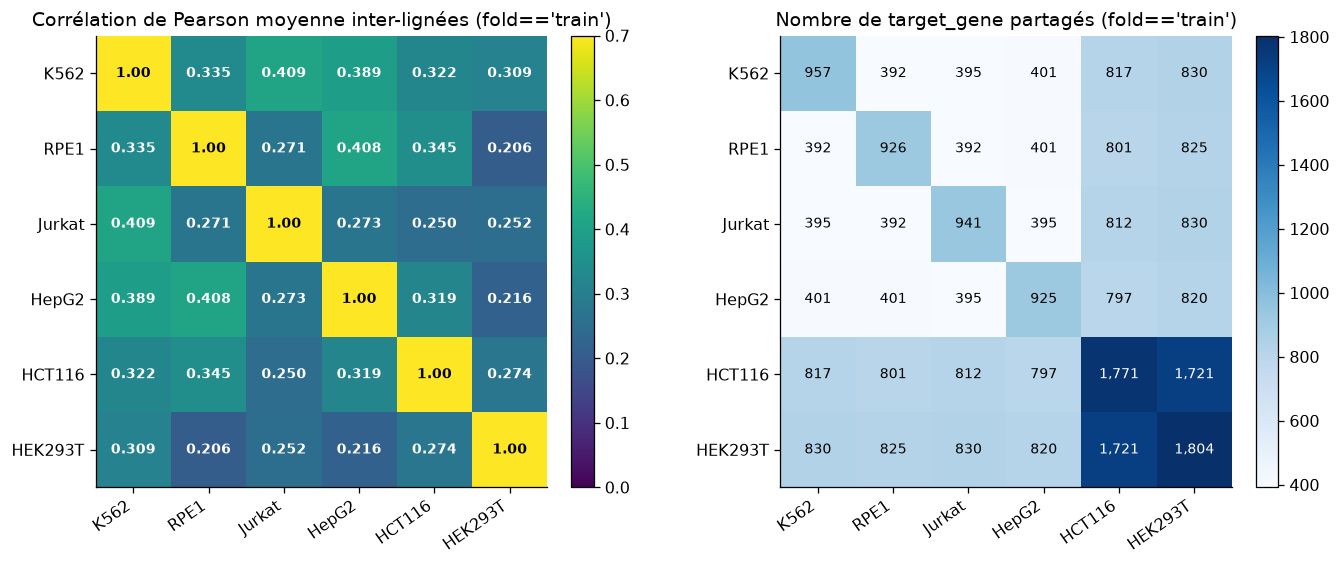

In [16]:
# Calcul de la matrice 6x6 sur fold=='train' uniquement (aucune fuite vers val)
lines_order = ["K562", "RPE1", "Jurkat", "HepG2", "HCT116", "HEK293T"]
lines_order = [l for l in lines_order if l in set(tr_sub["line"])]

scored_arr = np.asarray(scored_genes)

# Indexation rapide : line -> DataFrame (index=target_gene, cols=500 scored genes)
by_line_scored = {}
for line in lines_order:
    sub = tr_sub.loc[tr_sub["line"].eq(line)].set_index("target_gene")[scored_genes]
    by_line_scored[line] = sub


def rowwise_pearson_pair(df_a: pd.DataFrame, df_b: pd.DataFrame) -> np.ndarray:
    common = df_a.index.intersection(df_b.index)
    if len(common) == 0:
        return np.array([], dtype=np.float64)
    A = df_a.loc[common].to_numpy(dtype=np.float64)
    B = df_b.loc[common].to_numpy(dtype=np.float64)
    corrs = np.zeros(len(common), dtype=np.float64)
    for i, tg in enumerate(common):
        mask = (scored_arr != tg) & np.isfinite(A[i]) & np.isfinite(B[i])
        a = A[i, mask]
        b = B[i, mask]
        a = a - a.mean()
        b = b - b.mean()
        denom = np.linalg.norm(a) * np.linalg.norm(b)
        corrs[i] = 0.0 if denom == 0 else np.dot(a, b) / denom
    return corrs


n_lines = len(lines_order)
corr_mat = np.ones((n_lines, n_lines), dtype=np.float64)
count_mat = np.zeros((n_lines, n_lines), dtype=int)

for i, la in enumerate(lines_order):
    count_mat[i, i] = len(by_line_scored[la])
    for j in range(i + 1, n_lines):
        lb = lines_order[j]
        c = rowwise_pearson_pair(by_line_scored[la], by_line_scored[lb])
        count_mat[i, j] = count_mat[j, i] = len(c)
        val = float(c.mean()) if len(c) > 0 else np.nan
        corr_mat[i, j] = corr_mat[j, i] = val

corr_df = pd.DataFrame(corr_mat, index=lines_order, columns=lines_order)
count_df = pd.DataFrame(count_mat, index=lines_order, columns=lines_order)

# Statistiques d'amplitude par lignée (sur les 500 gènes scorés)
scale_stats = []
for line in lines_order:
    M = by_line_scored[line].to_numpy(dtype=np.float64)
    row_std = np.nanstd(M, axis=1)
    row_l2 = np.sqrt(np.nansum(M ** 2, axis=1))
    n_c = tr_sub.loc[tr_sub["line"].eq(line), "n_cells"]
    scale_stats.append({
        "line": line,
        "n_entries_train": len(M),
        "median_n_cells": n_c.median(),
        "mean_row_std": np.mean(row_std),
        "median_row_std": np.median(row_std),
        "mean_row_L2": np.mean(row_l2),
        "global_std": np.nanstd(M),
    })
scale_df = pd.DataFrame(scale_stats).set_index("line")
display(scale_df.round(4))

# Heatmap 6x6
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")

im0 = axes[0].imshow(corr_mat, vmin=0.0, vmax=0.7, cmap="viridis")
axes[0].set_xticks(range(n_lines), lines_order, rotation=35, ha="right")
axes[0].set_yticks(range(n_lines), lines_order)
axes[0].set_title("Corrélation de Pearson moyenne inter-lignées (fold=='train')")
for i in range(n_lines):
    for j in range(n_lines):
        txt = "1.00" if i == j else f"{corr_mat[i, j]:.3f}"
        color = "black" if corr_mat[i, j] > 0.45 else "white"
        axes[0].text(j, i, txt, ha="center", va="center", color=color, fontsize=9, fontweight="bold")
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(count_mat, cmap="Blues")
axes[1].set_xticks(range(n_lines), lines_order, rotation=35, ha="right")
axes[1].set_yticks(range(n_lines), lines_order)
axes[1].set_title("Nombre de target_gene partagés (fold=='train')")
for i in range(n_lines):
    for j in range(n_lines):
        color = "white" if count_mat[i, j] > count_mat.max() * 0.55 else "black"
        axes[1].text(j, i, f"{count_mat[i, j]:,}", ha="center", va="center", color=color, fontsize=9)
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

plt.show()

---
## 4. Effet de `n_cells` (qualité du pseudobulk et bruit)

Dans un profil pseudobulk, la variance du bruit d'échantillonnage décroît typiquement en $1 / n_{\text{cells}}$.
On vérifie :
1. La distribution de `n_cells` pour chaque lignée.
2. Si les entrées avec un petit `n_cells` ont une amplitude anormalement élevée (bruit !) ou une corrélation plus faible avec les autres lignées.

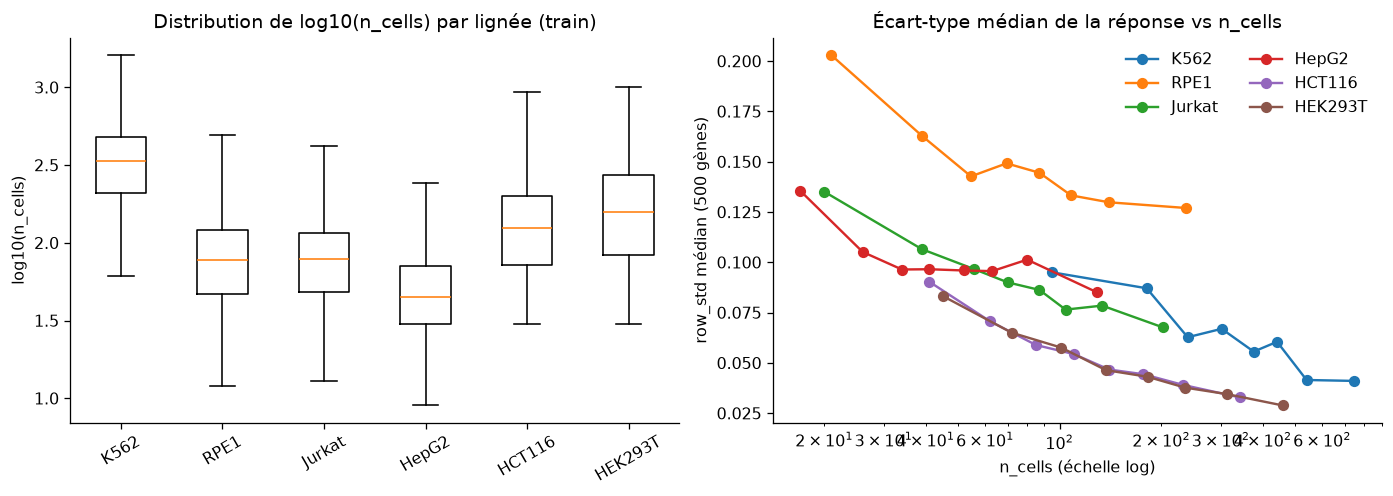

,count,mean,std,min,5%,25%,50%,75%,95%,max
line,,,,,,,,,,
HCT116,1771.0,152.7,107.8,30.0,39.5,72.0,125.0,201.5,359.0,940.0
HEK293T,1804.0,196.4,143.9,30.0,42.0,84.0,158.0,272.0,486.0,1008.0
HepG2,925.0,58.9,56.8,2.0,15.0,30.0,45.0,71.0,138.6,749.0
Jurkat,941.0,95.2,87.7,2.0,18.0,48.0,79.0,115.0,224.0,1142.0
K562,957.0,373.8,231.5,14.0,84.0,210.0,338.0,479.0,789.2,1875.0
RPE1,926.0,103.0,122.8,2.0,19.0,47.0,77.5,121.0,252.8,1759.0


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")

# Boxplot log10(n_cells) par lignée
data_box = [np.log10(tr_sub.loc[tr_sub["line"].eq(l), "n_cells"].clip(lower=1)) for l in lines_order]
axes[0].boxplot(data_box, tick_labels=lines_order, showfliers=False)
axes[0].set(title="Distribution de log10(n_cells) par lignée (train)", ylabel="log10(n_cells)")
axes[0].tick_params(axis="x", rotation=30)

# Relation n_cells vs écart-type de la réponse (par lignée)
tr_row_std = np.nanstd(tr_sub[scored_genes].to_numpy(dtype=np.float32), axis=1)
tmp = pd.DataFrame({
    "line": tr_sub["line"].values,
    "n_cells": tr_sub["n_cells"].values,
    "row_std": tr_row_std,
})
for line in lines_order:
    sub = tmp.loc[tmp["line"].eq(line)]
    bins = pd.qcut(sub["n_cells"], q=8, duplicates="drop")
    grp = sub.groupby(bins, observed=True).agg(x=("n_cells", "median"), y=("row_std", "median"))
    axes[1].plot(grp["x"], grp["y"], marker="o", label=line)

axes[1].set_xscale("log")
axes[1].set(title="Écart-type médian de la réponse vs n_cells", xlabel="n_cells (échelle log)", ylabel="row_std médian (500 gènes)")
axes[1].legend(frameon=False, ncol=2)

plt.show()

display(tmp.groupby("line")["n_cells"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(1))

---
## 5. Exploration de `baseline_expression.csv` & hypothèse biologique

`baseline_expression.csv` est **la seule description d'une lignée cellulaire autorisée** (expression CP10K dans les cellules contrôles non perturbées).
Hypothèse biologique à tester :
* Si un `target_gene` est très peu exprimé dans une lignée au départ (`baseline_expr` proche de 0), le knock-downer ne devrait presque rien changer (faible amplitude / bruit pur).
* La similarité des profils de contrôle entre lignées reflète-t-elle la similarité de leurs réponses aux perturbations ?

Aperçu de baseline_expression.csv :


,line,n_control_cells,source,ENSG00000000419,ENSG00000001084,ENSG00000001461,ENSG00000001497,ENSG00000001629
0,K562,91307.0,"Replogle et al. 2022, Cell (K562 genome-wide a...",0.696316,0.193357,0.111681,0.809133,0.139469
1,RPE1,14190.0,"Replogle et al. 2022, Cell (RPE1 essential-sca...",0.516645,0.101755,0.339419,0.361969,0.510447
2,Jurkat,12013.0,"Nadig et al. 2025, Nature Genetics (Jurkat ess...",0.767389,0.397888,0.223044,0.993092,0.362188
3,HepG2,4976.0,"Nadig et al. 2025, Nature Genetics (HepG2 esse...",0.902697,0.546614,0.123537,0.303512,0.220736
4,HCT116,NaN,"X-Atlas/Orion (Xaira Therapeutics, 2025), HCT1...",0.956698,0.411260,0.122985,0.614949,1.103760
5,HEK293T,NaN,"X-Atlas/Orion (Xaira Therapeutics, 2025), HEK2...",0.783550,0.399532,0.406394,1.176170,1.253580


Métadonnées baseline_expression :


,line,n_control_cells,source
0,K562,91307.0,"Replogle et al. 2022, Cell (K562 genome-wide a..."
1,RPE1,14190.0,"Replogle et al. 2022, Cell (RPE1 essential-sca..."
2,Jurkat,12013.0,"Nadig et al. 2025, Nature Genetics (Jurkat ess..."
3,HepG2,4976.0,"Nadig et al. 2025, Nature Genetics (HepG2 esse..."
4,HCT116,NaN,"X-Atlas/Orion (Xaira Therapeutics, 2025), HCT1..."
5,HEK293T,NaN,"X-Atlas/Orion (Xaira Therapeutics, 2025), HEK2..."


Matrice base_expr standardisée : (6, 6546)

Corrélation de Pearson des profils de contrôle log(1+CP10K) (6 546 gènes) :


line,K562,RPE1,Jurkat,HepG2,HCT116,HEK293T
line,,,,,,
K562,1.000,0.891,0.928,0.908,0.891,0.876
RPE1,0.891,1.000,0.891,0.911,0.897,0.840
Jurkat,0.928,0.891,1.000,0.883,0.881,0.862
HepG2,0.908,0.911,0.883,1.000,0.875,0.826
HCT116,0.891,0.897,0.881,0.875,1.000,0.915
HEK293T,0.876,0.840,0.862,0.826,0.915,1.000


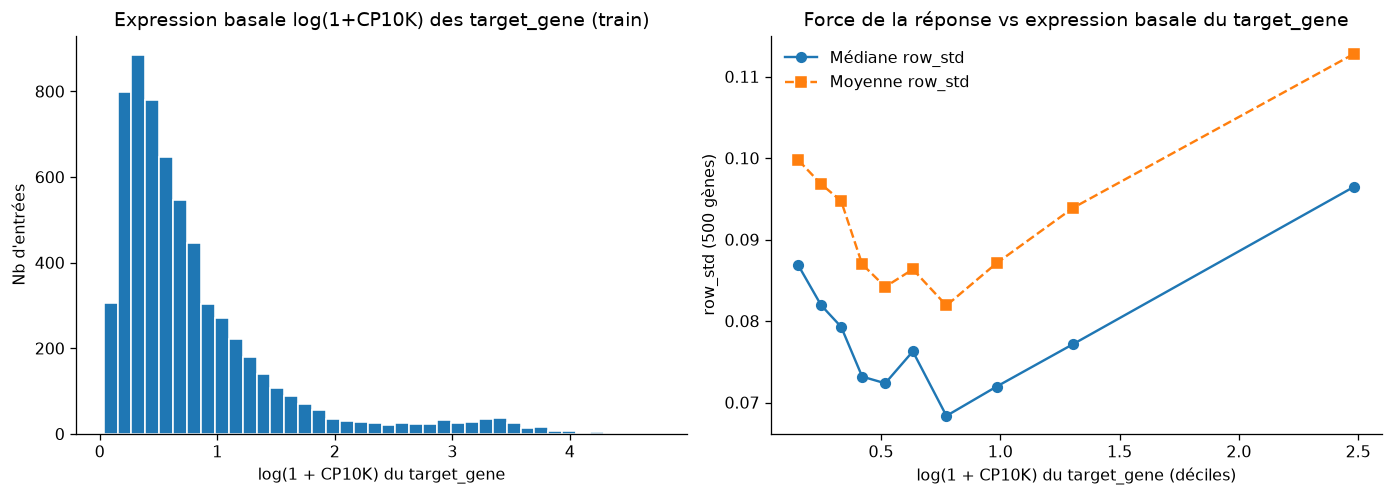

In [18]:
# Inspection dynamique du format de baseline_expression.csv
print("Aperçu de baseline_expression.csv :")
display(baseline_raw.iloc[:6, :8])

# Mise en forme standardisée : DataFrame (index=line, columns=all_genes) en CP10K
gene_set = set(all_genes)
gene_cols_in_base = [c for c in baseline_raw.columns if c in gene_set]

if len(gene_cols_in_base) > 1000:
    # Format : 1 ligne = 1 cell line, gènes en colonnes
    line_col = next((c for c in baseline_raw.columns if baseline_raw[c].astype(str).isin(lines_order).any()), baseline_raw.columns[0])
    meta_base_cols = [c for c in baseline_raw.columns if c not in gene_set]
    print("Métadonnées baseline_expression :")
    display(baseline_raw[meta_base_cols])
    base_expr = baseline_raw.set_index(line_col)[all_genes].astype(np.float64)
else:
    # Format transposé : gènes en lignes, lignées en colonnes
    gene_id_col = next((c for c in baseline_raw.columns if baseline_raw[c].astype(str).isin(gene_set).any()), baseline_raw.columns[0])
    base_expr = baseline_raw.set_index(gene_id_col)[[l for l in lines_order if l in baseline_raw.columns]].T[all_genes].astype(np.float64)

base_log = np.log1p(base_expr)
print(f"Matrice base_expr standardisée : {base_expr.shape}")

# Corrélation des expressions basales log(1+CP10K) entre les 6 lignées
base_corr = base_log.loc[lines_order].T.corr()
print("\nCorrélation de Pearson des profils de contrôle log(1+CP10K) (6 546 gènes) :")
display(base_corr.round(3))

# Test de l'hypothèse biologique : expression basale du target_gene vs amplitude de sa réponse
target_base_log = np.array([
    base_log.loc[l, g] if (l in base_log.index and g in base_log.columns) else np.nan
    for l, g in zip(tr_sub["line"], tr_sub["target_gene"])
])

bio_df = pd.DataFrame({
    "line": tr_sub["line"].values,
    "target_base_log": target_base_log,
    "row_std": tr_row_std,
    "n_cells": tr_sub["n_cells"].values,
}).dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")

axes[0].hist(bio_df["target_base_log"], bins=40, edgecolor="white")
axes[0].set(title="Expression basale log(1+CP10K) des target_gene (train)", xlabel="log(1 + CP10K) du target_gene", ylabel="Nb d'entrées")

bins_expr = pd.qcut(bio_df["target_base_log"], q=10, duplicates="drop")
grp_bio = bio_df.groupby(bins_expr, observed=True).agg(
    x=("target_base_log", "median"),
    y_med=("row_std", "median"),
    y_mean=("row_std", "mean"),
)
axes[1].plot(grp_bio["x"], grp_bio["y_med"], marker="o", label="Médiane row_std")
axes[1].plot(grp_bio["x"], grp_bio["y_mean"], marker="s", linestyle="--", label="Moyenne row_std")
axes[1].set(title="Force de la réponse vs expression basale du target_gene", xlabel="log(1 + CP10K) du target_gene (déciles)", ylabel="row_std (500 gènes)")
axes[1].legend(frameon=False)

plt.show()

---
## 6. Les 500 gènes scorés vs 6 546 gènes mesurés, spectre SVD et `line_mean_response.csv`

1. Les 500 gènes scorés sont-ils les gènes les plus variables / les plus exprimés ?
2. Quelle est la **dimension intrinsèque** des réponses (variance expliquée par les $k$ premières composantes SVD sur les 500 et 6 546 gènes) ?
3. Quelle est l'ampleur de `line_mean_response.csv` par rapport aux réponses centrées ?

Statistiques des gènes (scored=True vs scored=False) :


resp_std                                                          \
          count    mean     std     min     25%     50%     75%     max   
scored                                                                    
False    6046.0  0.0598  0.0174  0.0265  0.0480  0.0576  0.0684  0.2459   
True      500.0  0.1045  0.0310  0.0663  0.0857  0.0942  0.1118  0.2729   

       base_log_mean                                                          
               count    mean     std     min     25%     50%     75%     max  
scored                                                                        
False         6046.0  0.4572  0.2921  0.0817  0.2493  0.3734  0.5784  2.2673  
True           500.0  1.8258  0.9150  0.4653  1.1234  1.5457  2.4069  4.8265

Top   5 composantes -> Var expliquée (500 scorés): 51.7% | (6 546 gènes): 31.7%
Top  10 composantes -> Var expliquée (500 scorés): 60.6% | (6 546 gènes): 37.8%
Top  20 composantes -> Var expliquée (500 scorés): 68.6% | (6 546 gènes): 44.0%
Top  50 composantes -> Var expliquée (500 scorés): 77.8% | (6 546 gènes): 52.9%
Top 100 composantes -> Var expliquée (500 scorés): 84.4% | (6 546 gènes): 60.3%
Top 200 composantes -> Var expliquée (500 scorés): 91.4% | (6 546 gènes): 68.9%

Aperçu de line_mean_response.csv :


,line,ENSG00000000419,ENSG00000001084,ENSG00000001461,ENSG00000001497,ENSG00000001629,ENSG00000001631,ENSG00000002330
0,K562,-0.015651,0.003285,0.005023,-0.033714,0.007665,0.006517,0.014039
1,RPE1,-0.033855,0.021310,0.048792,-0.054682,0.026764,-0.004827,0.002310
2,Jurkat,-0.031646,-0.002421,0.013356,-0.044281,0.007272,0.016824,0.008722
3,HepG2,-0.021283,0.017657,0.023054,-0.036604,0.001271,-0.006559,0.004739
4,HCT116,-0.004399,0.006217,0.011351,-0.011623,0.019161,0.004969,-0.001518
5,HEK293T,-0.004153,0.001647,0.004747,-0.009105,0.006454,0.007797,0.011566


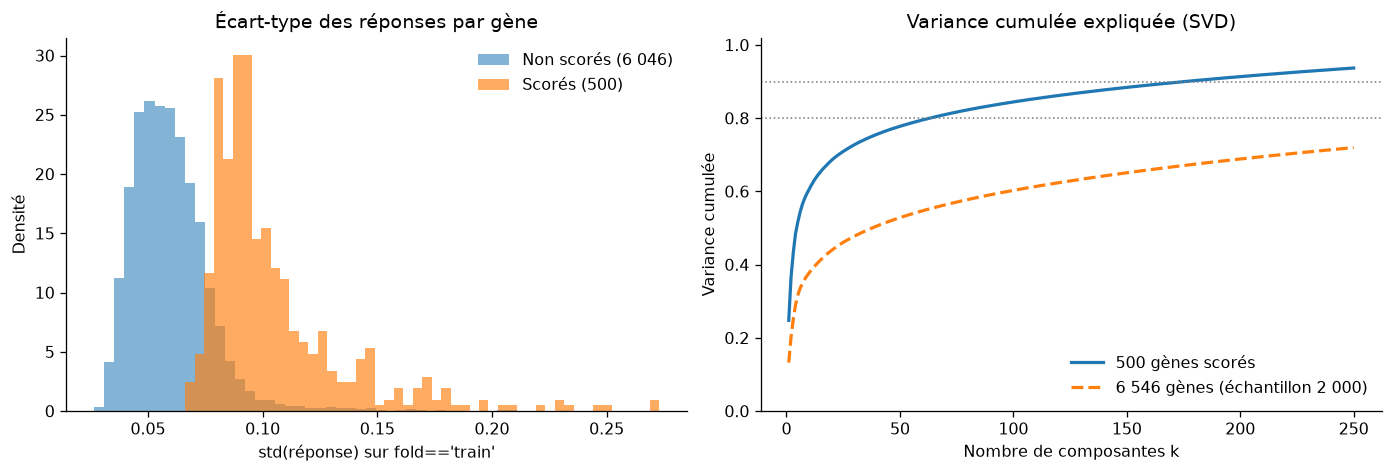

In [ ]:
# 1. Comparaison 500 gènes scorés vs 6 046 non scorés
Y_tr_all = tr_sub[all_genes].to_numpy(dtype=np.float32)
gene_std_all = pd.Series(np.nanstd(Y_tr_all, axis=0), index=all_genes)
gene_base_mean = base_log.mean(axis=0)

comp_genes = pd.DataFrame({
    "resp_std": gene_std_all,
    "base_log_mean": gene_base_mean,
    "scored": genes_df.set_index("gene_id")["scored"],
})
print("Statistiques des gènes (scored=True vs scored=False) :")
display(comp_genes.groupby("scored")[["resp_std", "base_log_mean"]].describe().round(4))

# 2. Spectre SVD sur les 500 gènes scorés (et sur 6 546 gènes) après imputation NaN -> 0
Y_500 = np.nan_to_num(tr_sub[scored_genes].to_numpy(dtype=np.float32), nan=0.0)
_, s_500, _ = np.linalg.svd(Y_500, full_matrices=False)
var_500 = np.cumsum(s_500 ** 2) / np.sum(s_500 ** 2)

# SVD tronquée rapide via matrice de Gram ou SVD complète (7324 x 6546 -> faisable mais on peut prendre un sous-ensemble ou Gram)
# Note : on calcule sur 2000 lignes aléatoires pour un spectre 6546 gènes instantané (<2s)
rng = np.random.default_rng(42)
sub_idx = rng.choice(len(Y_tr_all), size=min(2000, len(Y_tr_all)), replace=False)
Y_6546_sub = np.nan_to_num(Y_tr_all[sub_idx], nan=0.0)
_, s_6546, _ = np.linalg.svd(Y_6546_sub, full_matrices=False)
var_6546 = np.cumsum(s_6546 ** 2) / np.sum(s_6546 ** 2)

for k in [5, 10, 20, 50, 100, 200]:
    print(f"Top {k:>3d} composantes -> Var expliquée (500 scorés): {var_500[k-1]:.1%} | (6 546 gènes): {var_6546[k-1]:.1%}")

# 3. Aperçu de line_mean_response.csv
print("\nAperçu de line_mean_response.csv :")
display(line_mean_raw.iloc[:6, :8])

# Graphiques
fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), layout="constrained")

axes[0].hist(comp_genes.loc[~comp_genes["scored"], "resp_std"], bins=50, density=True, alpha=0.55, label="Non scorés (6 046)")
axes[0].hist(comp_genes.loc[comp_genes["scored"], "resp_std"], bins=50, density=True, alpha=0.65, label="Scorés (500)")
axes[0].set(title="Écart-type des réponses par gène", xlabel="std(réponse) sur fold=='train'", ylabel="Densité")
axes[0].legend(frameon=False)

axes[1].plot(np.arange(1, 251), var_500[:250], linewidth=2, label="500 gènes scorés")
axes[1].plot(np.arange(1, 251), var_6546[:250], linewidth=2, linestyle="--", label="6 546 gènes (échantillon 2 000)")
axes[1].axhline(0.8, color="gray", linestyle=":", linewidth=1)
axes[1].axhline(0.9, color="gray", linestyle=":", linewidth=1)
axes[1].set(title="Variance cumulée expliquée (SVD)", xlabel="Nombre de composantes k", ylabel="Variance cumulée", ylim=(0, 1.02))
axes[1].legend(frameon=False)

plt.show()

---
## 7. Diagnostic fin des erreurs de la baseline (`00_baseline` sur `fold == "val"`)

On décompose le score de `0.42902` ligne par ligne pour voir exactement **où la baseline échoue** :
* Par nombre de lignées sources disponibles (1 vs 2 vs 3 vs 4 vs 5).
* Par niveau d'expression basale du `target_gene` dans la lignée cible.
* Par lignée cible (`HepG2`, `Jurkat`, `K562`, `RPE1`).
* Les 10 pires prédictions (erreurs négatives ou proches de 0).

Vérification score Pearson global val : 0.42902

--- Score par nombre total de lignées sources ---


,count,mean,median,std
n_src_total,,,,
1,74,0.3865,0.3653,0.2398
2,73,0.3828,0.3855,0.2433
3,620,0.4284,0.4425,0.2177
4,318,0.4325,0.4603,0.2303
5,88,0.4950,0.5247,0.2002



--- Score selon disponibilité de lignées CORE vs uniquement extra_line ---


,count,mean,median,std
only_extra,,,,
False,1173,0.429,0.4508,0.224



--- Score par quintile d'expression basale du target_gene ---


,count,mean,median
expr_bin,,,
"(0.0625, 0.241]",201,0.4310,0.4508
"(0.241, 0.401]",200,0.4429,0.4520
"(0.401, 0.624]",200,0.4004,0.4317
"(0.624, 1.031]",200,0.4311,0.4223
"(1.031, 4.605]",200,0.4203,0.4090



--- Top 10 pires entrées en validation ---


,id,line,target_symbol,n_cells,n_src_total,only_extra,target_base_log,true_std,pearson
442,RPE1_ENSG00000144736,RPE1,SHQ1,165,4,False,0.1014,0.0835,-0.3406
998,HepG2_ENSG00000130695,HepG2,CEP85,57,3,False,NaN,0.0960,-0.2838
436,RPE1_ENSG00000142731,RPE1,PLK4,205,4,False,0.1395,0.1306,-0.2663
403,RPE1_ENSG00000130695,RPE1,CEP85,72,3,False,NaN,0.1447,-0.2542
516,RPE1_ENSG00000172757,RPE1,CFL1,159,3,False,2.9749,0.1422,-0.2529
966,HepG2_ENSG00000114346,HepG2,ECT2,20,3,False,0.4501,0.1062,-0.2399
849,Jurkat_ENSG00000214113,Jurkat,LYRM4,41,3,False,0.5289,0.0967,-0.2397
682,Jurkat_ENSG00000119041,Jurkat,GTF3C3,49,3,False,0.4290,0.1255,-0.2269
55,K562_ENSG00000110048,K562,OSBP,273,3,False,0.4395,0.0428,-0.2140
333,RPE1_ENSG00000101639,RPE1,CEP192,70,1,False,0.2818,0.1348,-0.1998


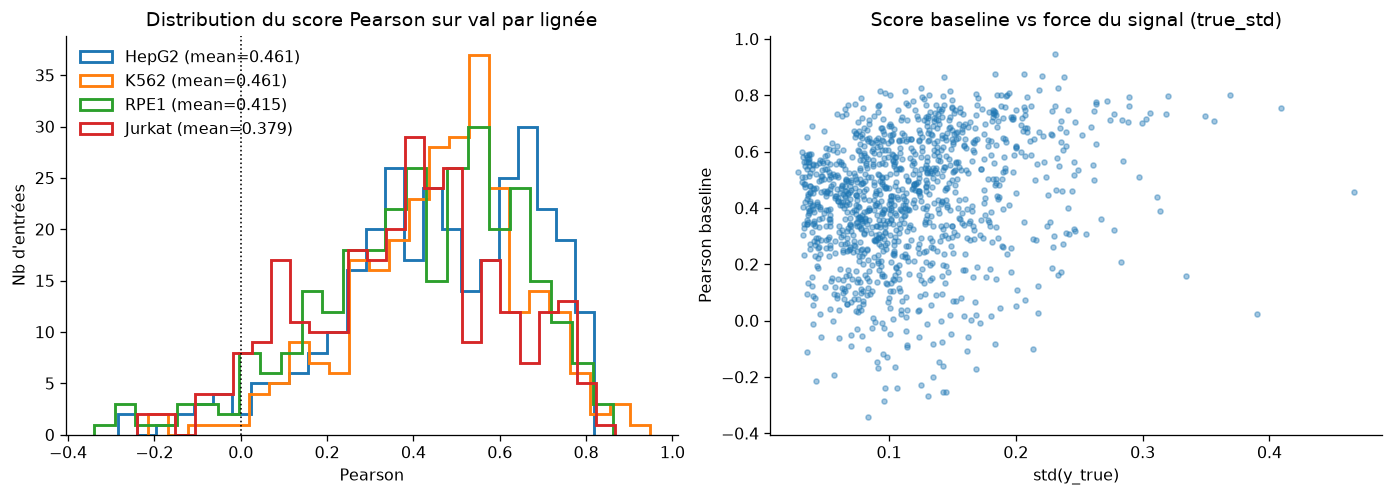

In [ ]:
# Recalcul des prédictions baseline (moyenne des autres lignées dans fold=='train', 6 lignées)
mean_by_gene = tr_sub.groupby("target_gene")[scored_genes].mean()
y_val_true = va_sub[scored_genes].to_numpy(dtype=np.float64)
y_val_pred = mean_by_gene.reindex(va_sub["target_gene"].values).to_numpy(dtype=np.float64)
y_val_pred = np.nan_to_num(y_val_pred, nan=0.0)

val_scores = np.zeros(len(va_sub), dtype=np.float64)
val_true_std = np.zeros(len(va_sub), dtype=np.float64)
for i, tg in enumerate(va_sub["target_gene"].values):
    mask = (scored_arr != tg) & np.isfinite(y_val_true[i])
    t = y_val_true[i, mask]
    p = y_val_pred[i, mask]
    val_true_std[i] = t.std()
    tc, pc = t - t.mean(), p - p.mean()
    denom = np.linalg.norm(tc) * np.linalg.norm(pc)
    val_scores[i] = 0.0 if denom == 0 else np.dot(tc, pc) / denom

diag_df = va_sub[["id", "line", "target_gene", "target_symbol", "n_cells"]].copy().reset_index(drop=True)
diag_df["pearson"] = val_scores
diag_df["true_std"] = val_true_std
diag_df["n_src_total"] = val_src["n_src_total"].values
diag_df["n_src_core"] = val_src["n_src_core"].values
diag_df["only_extra"] = val_src["only_extra"].values
diag_df["target_base_log"] = [
    base_log.loc[l, g] if (l in base_log.index and g in base_log.columns) else np.nan
    for l, g in zip(diag_df["line"], diag_df["target_gene"])
]

print(f"Vérification score Pearson global val : {diag_df['pearson'].mean():.5f}")

print("\n--- Score par nombre total de lignées sources ---")
display(diag_df.groupby("n_src_total")["pearson"].agg(["count", "mean", "median", "std"]).round(4))

print("\n--- Score selon disponibilité de lignées CORE vs uniquement extra_line ---")
display(diag_df.groupby("only_extra")["pearson"].agg(["count", "mean", "median", "std"]).round(4))

print("\n--- Score par quintile d'expression basale du target_gene ---")
diag_df["expr_bin"] = pd.qcut(diag_df["target_base_log"], q=5, duplicates="drop")
display(diag_df.groupby("expr_bin", observed=True)["pearson"].agg(["count", "mean", "median"]).round(4))

print("\n--- Top 10 pires entrées en validation ---")
display(diag_df.sort_values("pearson").head(10)[["id", "line", "target_symbol", "n_cells", "n_src_total", "only_extra", "target_base_log", "true_std", "pearson"]].round(4))

# Distribution des scores Pearson par lignée
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
for line in ["HepG2", "K562", "RPE1", "Jurkat"]:
    s = diag_df.loc[diag_df["line"].eq(line), "pearson"]
    axes[0].hist(s, bins=25, histtype="step", linewidth=1.8, label=f"{line} (mean={s.mean():.3f})")
axes[0].axvline(0, color="black", linestyle=":", linewidth=1)
axes[0].set(title="Distribution du score Pearson sur val par lignée", xlabel="Pearson", ylabel="Nb d'entrées")
axes[0].legend(frameon=False)

axes[1].scatter(diag_df["true_std"], diag_df["pearson"], s=10, alpha=0.4)
axes[1].set(title="Score baseline vs force du signal (true_std)", xlabel="std(y_true)", ylabel="Pearson baseline")

plt.show()

In [ ]:
print("=== 1. Matrice de corrélation 6x6 (fold=='train') ===")
print(corr_df.round(3).to_string())

print("\n=== 2. Origine des 14 300 NaN inattendus ===")
unexp_mask = nan_mask & ~expected_nan
unexp_by_line = pd.Series(unexp_mask.sum(axis=1), index=train_df["line"]).groupby(level=0).sum()
unexp_in_scored = int(unexp_mask[:, [gene_to_idx[g] for g in scored_genes]].sum())
unexp_cols = (unexp_mask.sum(axis=0) > 0).sum()
print("Par lignée :", unexp_by_line.to_dict())
print(f"Dans les 500 gènes scorés : {unexp_in_scored:,} | Nb de gènes touchés : {unexp_cols:,}")

print("\n=== 3. Spectre SVD ===")
for k in [5, 10, 20, 50, 100, 200]:
    print(f"k={k:>3d} -> 500 scorés: {var_500[k-1]:.1%} | 6 546 gènes: {var_6546[k-1]:.1%}")

print("\n=== 4. Diagnostic 00_baseline sur val ===")
print("Par n_src_total :\n", diag_df.groupby("n_src_total")["pearson"].agg(["count", "mean", "median"]).round(4).to_string())
print("\nPar quintile expression basale :\n", diag_df.groupby("expr_bin", observed=True)["pearson"].agg(["count", "mean", "median"]).round(4).to_string())

=== 1. Matrice de corrélation 6x6 (fold=='train') ===
          K562   RPE1  Jurkat  HepG2  HCT116  HEK293T
K562     1.000  0.335   0.409  0.389   0.322    0.309
RPE1     0.335  1.000   0.271  0.408   0.345    0.206
Jurkat   0.409  0.271   1.000  0.273   0.250    0.252
HepG2    0.389  0.408   0.273  1.000   0.319    0.216
HCT116   0.322  0.345   0.250  0.319   1.000    0.274
HEK293T  0.309  0.206   0.252  0.216   0.274    1.000

=== 2. Origine des 14 300 NaN inattendus ===
Par lignée : {'HCT116': 7084, 'HEK293T': 7216, 'HepG2': 0, 'Jurkat': 0, 'K562': 0, 'RPE1': 0}
Dans les 500 gènes scorés : 0 | Nb de gènes touchés : 4

=== 3. Spectre SVD ===
k=  5 -> 500 scorés: 51.7% | 6 546 gènes: 31.7%
k= 10 -> 500 scorés: 60.6% | 6 546 gènes: 37.8%
k= 20 -> 500 scorés: 68.6% | 6 546 gènes: 44.0%
k= 50 -> 500 scorés: 77.8% | 6 546 gènes: 52.9%
k=100 -> 500 scorés: 84.4% | 6 546 gènes: 60.3%
k=200 -> 500 scorés: 91.4% | 6 546 gènes: 68.9%

=== 4. Diagnostic 00_baseline sur val ===
Par n_src_total :

---
## 8. Synthèse & décisions 

Note ici les 4-5 observations chiffrées obtenues ci-dessus qui guideront nos premiers vrais modèles :
1. **Stratégie CV** : est-ce que `fold == "val"` est suffisant ou faut-il construire un 5-fold `GroupKFold` sur `target_gene` qui imite exactement le nombre de lignées masquées par gène dans `test.csv` ?
2. **Pondération & normalisation inter-lignées** : quelles paires de lignées sont les plus proches dans la matrice $6 \times 6$ ? Y a-t-il un gros écart d'amplitude (`mean_row_std`) entre labos qui justifie une standardisation par ligne avant moyennage ?
3. **Effet `n_cells`** : est-ce que pondérer les lignées sources par une fonction de `n_cells` (ex. $\sqrt{n_{\text{cells}}}$ ou $\log(1 + n_{\text{cells}})$) a du sens ?
4. **Traduction inter-lignées (`Ridge` / `SVD`)** : compte tenu de la dimension intrinsèque vue en SVD (Section 6), utiliser les **6 546 gènes sources** (pas seulement les 500 scorés !) pour prédire les 500 gènes cibles est-il prometteur ?